# NLP - PROJECT: SpamLens (Transformer Models)

| Model | Idea |
|---|---|
| DistilBERT | Plain BERT-style fine-tuning (baseline) |
| RoBERTa + SetFit | Same encoder family, trained on pairs of messages from a small subset, then a logistic regression |
| FLAN-T5 | A very different model (encoder-decoder) |

**How to run**
1. Run `traditional_models.ipynb` first: it creates the train, validation and test data in Google Drive (`MyDrive/SpamLens/data`).
2. Open this notebook in Google Colab and choose a **T4 GPU** (`Runtime > Change runtime type`).
3. Run the `pip install` cell, click `Runtime > Restart session`, then run all cells from the top (`Runtime > Run all`).
4. To evaluate the saved models without training them again, set `train_distilbert`, `train_setfit` and `train_flan_t5` to `False` in section 1.

Training time on a T4 GPU based on my google colab(Christian Verrell) it could differ for different colab: DistilBERT about 15 minutes, SetFit about 15 minutes, FLAN-T5 about 1 hour. Without training, the notebook needs about 15 minutes.

## 1. Preparation

In [6]:
!pip install -q transformers==4.57.6 datasets==4.8.5 accelerate==1.15.0 setfit==1.2.0 sentence-transformers==5.7.0 scikit-learn==1.9.1

**Important:** after the first install, click `Runtime > Restart session`, then run the notebook again from the top. Colab keeps its own newer versions in memory until the session restarts.

A red "ERROR: pip's dependency resolver" message about gradio, diffusers or huggingface-hub can be ignored: this project does not use those packages.

In [7]:
# Check the library versions: they must match app.py, otherwise the saved models may not work in the app
import sklearn
import transformers

print("transformers:", transformers.__version__)
print("scikit-learn:", sklearn.__version__)

if transformers.__version__ != "4.57.6" or sklearn.__version__ != "1.9.1":
    raise SystemExit("Wrong versions. Click Runtime > Restart session, then run the notebook again from the top.")

transformers: 4.57.6
scikit-learn: 1.9.1


In [8]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU undetected!")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [9]:
# Import Libraries
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, EarlyStoppingCallback, Trainer, TrainingArguments, set_seed

In [10]:
# Save everything on Google Drive so it is kept after the Colab session ends
from google.colab import drive
import os

drive.mount("/content/drive")

project_folder = "/content/drive/MyDrive/SpamLens"
data_folder = os.path.join(project_folder, "data")
model_folder = os.path.join(project_folder, "models")
table_folder = os.path.join(project_folder, "results", "tables")
figure_folder = os.path.join(project_folder, "results", "figures")

for folder in [data_folder, model_folder, table_folder, figure_folder]:
    os.makedirs(folder, exist_ok=True)

print("Folder ready:", project_folder)

Mounted at /content/drive
Folder ready: /content/drive/MyDrive/SpamLens


In [11]:
# Set to False to skip a model that is already trained and saved in model_folder
train_distilbert = True
train_setfit = True
train_flan_t5 = True

In [12]:
# Load the data created by traditional_models.ipynb
train_data = pd.read_csv(os.path.join(data_folder, "train.csv"))
validation_data = pd.read_csv(os.path.join(data_folder, "validation.csv"))
test_data = pd.read_csv(os.path.join(data_folder, "test.csv"))
unused_ham_data = pd.read_csv(os.path.join(data_folder, "unused_ham_pool.csv"))

train_labels = train_data["label"].to_numpy()
validation_labels = validation_data["label"].to_numpy()
test_labels = test_data["label"].to_numpy()

print("train:", train_data.shape)
print("validation:", validation_data.shape)
print("test:", test_data.shape)

train: (13406, 3)
validation: (2873, 3)
test: (2873, 3)


## 2. Preprocessing

In [13]:
# Text normalization: replace links, emails, money, phone numbers and other numbers with placeholders.
# The two datasets hide private data differently ("XXXX", "<#>"), so without this step a model
# could learn "contains XXXX = spam". The same function is used in app.py.
import re
import unicodedata

digit = r"[0-9X]"  # a real digit, or the uppercase X that the datasets use to hide digits
url_pattern = re.compile(r"(?:https?://|www\.)\S+|\b[a-z0-9-]+(?:\.[a-z0-9-]+)*\.(?:com|net|org|ly|me|co|info|io|uk|au|in|us|xyz|top|link|site|online|club|app|gl|biz)\b(?:/\S*)?", re.I)
email_pattern = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
money_pattern = re.compile(rf"(?:[£$€₹]|\b(?:rs|inr|usd|gbp|eur|php|ngn|ksh|aud|sgd)\.?)\s?{digit}[0-9X,.]*(?:\s?(?:k|m|lakh|lac|lacs|crore|cr)\b)?", re.I)
phone_pattern = re.compile(rf"(?<![A-Za-z0-9])\+?{digit}(?:[\s\-()]?{digit}){{6,}}(?![A-Za-z0-9])")
number_pattern = re.compile(rf"(?<![A-Za-z0-9]){digit}*\d{digit}*(?:[.,:/]{digit}+)*(?![A-Za-z0-9])|\bX{{2,}}\b|(?<![A-Za-z'\-])X(?![A-Za-z'\-])")

def normalize(text):
    text = unicodedata.normalize("NFKC", str(text))

    # 1. Masks already used by the datasets
    text = re.sub(r"<URL>", " [URL] ", text, flags=re.I)
    text = re.sub(r"<EMAIL>", " [EMAIL] ", text, flags=re.I)
    text = re.sub(r"<(?:#|DECIMAL|TIME)>", " [NUM] ", text, flags=re.I)

    # 2. Real values
    text = email_pattern.sub(" [EMAIL] ", text)
    text = url_pattern.sub(" [URL] ", text)
    text = money_pattern.sub(" [MONEY] ", text)
    text = phone_pattern.sub(" [PHONE] ", text)
    text = number_pattern.sub(" [NUM] ", text)

    # 3. Merge repeated [NUM] and extra spaces
    text = re.sub(r"(?:\[NUM\]\s*){2,}", "[NUM] ", text)
    return re.sub(r"\s+", " ", text).strip()

In [14]:
# DistilBERT is uncased, so normalized text is enough.
# RoBERTa and FLAN-T5 see capital letters, so we also lowercase (capitals must not become a shortcut),
# and remove typed tokens such as "</s>" that have a special meaning for the T5 tokenizer.
def normalize_lowercase(text):
    return re.sub(r"</?s>|<pad>|<unk>|<mask>|<extra_id_\d+>", " ", normalize(text).lower())

print(normalize("WINNER!! Call 09061701461 to claim £900"))
print(normalize_lowercase("WINNER!! Call 09061701461 to claim £900"))

WINNER!! Call [PHONE] to claim [MONEY]
winner!! call [phone] to claim [money]


In [15]:
from sklearn.metrics import f1_score

# Validation score used by the Trainer to pick the best epoch
def compute_metrics(evaluation):
    logits, labels = evaluation
    predictions = np.argmax(logits, axis=-1)
    return {"macro_f1": f1_score(labels, predictions, average="macro")}


def make_dataset(texts, labels, tokenizer):
    dataset = Dataset.from_dict({"text": texts, "labels": labels.tolist()})
    return dataset.map(lambda batch: tokenizer(batch["text"], truncation=True, max_length=128), batched=True, remove_columns=["text"])


id2label = {0: "ham", 1: "spam"}
label2id = {"ham": 0, "spam": 1}

## 3. DistilBERT

In [16]:
distilbert_folder = os.path.join(model_folder, "distilbert")

if train_distilbert:
    set_seed(42)
    tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
    train_dataset = make_dataset(train_data["text"].apply(normalize).tolist(), train_labels, tokenizer)
    validation_dataset = make_dataset(validation_data["text"].apply(normalize).tolist(), validation_labels, tokenizer)

    model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2, id2label=id2label, label2id=label2id)

    training_args = TrainingArguments(
        output_dir="/content/checkpoints/distilbert",

        # Training
        num_train_epochs=4,
        per_device_train_batch_size=32,
        per_device_eval_batch_size=32,
        learning_rate=2e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,

        # Evaluation: the validation set picks the best epoch
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",

        # Performance
        fp16=True,

        # Logging
        logging_steps=50,
        save_total_limit=1,
        report_to="none",

        # Reproducibility
        seed=42,
        data_seed=42
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=validation_dataset,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]  # stop when validation stops improving
    )

    trainer.train()
    print("Best validation Macro F1:", trainer.state.best_metric)

    # Safety check: a broken training (for example a "nan" loss) predicts only one class and scores about 0.33
    if trainer.state.best_metric < 0.9:
        raise SystemExit("DistilBERT training failed (validation Macro F1 below 0.9), so the model was NOT saved. Check the training log above.")

    trainer.save_model(distilbert_folder)
    tokenizer.save_pretrained(distilbert_folder)
    print("DistilBERT saved:", distilbert_folder)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/13406 [00:00<?, ? examples/s]

Map:   0%|          | 0/2873 [00:00<?, ? examples/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1
1,0.039000,0.037512,0.989906
2,0.029600,0.042388,0.988861


Best validation Macro F1: 0.9899057818860415
DistilBERT saved: /content/drive/MyDrive/SpamLens/models/distilbert


## 4. RoBERTa + SetFit

SetFit has two steps:
1. Fine-tune a sentence encoder with **pairs** of messages (same class = similar, different class = not similar), using only 256 messages per class.
2. Turn every training message into a vector (embedding) and train a logistic regression on those vectors.

We tried 2 encoders x 3 subset sizes x 3 values of C; the best on validation is used below (all results: `results/tables/setfit_selection.csv`).

In [17]:
from setfit import SetFitModel
from setfit import Trainer as SetFitTrainer
from setfit import TrainingArguments as SetFitTrainingArguments
from sklearn.linear_model import LogisticRegression

setfit_folder = os.path.join(model_folder, "roberta_setfit")

if train_setfit:
    # Full precision, as in the original experiment (the DistilBERT cell leaves "fp16" switched on for the session)
    os.environ["ACCELERATE_MIXED_PRECISION"] = "no"
    set_seed(42)
    train_lowercase = pd.DataFrame({"text": train_data["text"].apply(normalize_lowercase), "label": train_labels})

    # 1. Small balanced subset: 256 messages per class
    subset = train_lowercase.groupby("label", group_keys=False)[["text", "label"]].sample(n=256, random_state=42)

    # 2. Fine-tune the sentence encoder on pairs from the subset
    setfit_model = SetFitModel.from_pretrained("sentence-transformers/stsb-roberta-base-v2", device="cuda")
    setfit_args = SetFitTrainingArguments(batch_size=32, num_epochs=1, num_iterations=20, seed=42, report_to=[], output_dir="/content/checkpoints/setfit")
    SetFitTrainer(model=setfit_model, args=setfit_args, train_dataset=Dataset.from_pandas(subset, preserve_index=False)).train()

    # 3. Logistic regression on the embeddings of ALL training messages
    train_embeddings = setfit_model.encode(train_lowercase["text"].tolist(), batch_size=64)
    setfit_model.model_head = LogisticRegression(C=10, max_iter=3000, solver="liblinear", random_state=42).fit(train_embeddings, train_labels)

    setfit_model.save_pretrained(setfit_folder)
    print("RoBERTa + SetFit saved:", setfit_folder)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


config.json:   0%|          | 0.00/675 [00:00<?, ?B/s]

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (13 outputs left out)

Step,Training Loss
1,0.376700
50,0.209100
100,0.009300
150,0.000400
200,0.000200
250,0.000200
300,0.000100
350,0.000100
400,0.000100
450,0.000100


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


RoBERTa + SetFit saved: /content/drive/MyDrive/SpamLens/models/roberta_setfit


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. FLAN-T5

`google/flan-t5-base` with a classification head. We tried learning rates 2e-5 and 1e-4; 2e-5 was better on validation (`results/tables/flan_t5_selection.csv`). Training uses full precision because fp16 made the loss NaN.

In [18]:
flan_t5_folder = os.path.join(model_folder, "flan_t5")

if train_flan_t5:
    # The DistilBERT cell (fp16=True) leaves this setting on "fp16" for the whole session, and fp16=False below
    # does not switch it back. FLAN-T5 must train in full precision (fp16 makes the loss "nan"), so reset it here.
    os.environ["ACCELERATE_MIXED_PRECISION"] = "no"
    set_seed(42)
    tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-base")
    train_dataset = make_dataset(train_data["text"].apply(normalize_lowercase).tolist(), train_labels, tokenizer)
    validation_dataset = make_dataset(validation_data["text"].apply(normalize_lowercase).tolist(), validation_labels, tokenizer)

    # dtype=torch.float32: always full precision; with half precision the T5 loss becomes "nan"
    model = AutoModelForSequenceClassification.from_pretrained("google/flan-t5-base", num_labels=2, id2label=id2label, label2id=label2id, dtype=torch.float32)
    model.config.use_cache = False  # saves GPU memory

    training_args = TrainingArguments(
        output_dir="/content/checkpoints/flan_t5",
        num_train_epochs=4,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        learning_rate=2e-5,
        weight_decay=0.01,
        warmup_ratio=0.1,
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_steps=100,  # show the training loss often, so a "nan" loss is seen early
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        fp16=False,
        save_total_limit=1,
        report_to="none",
        seed=42,
        data_seed=42
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=validation_dataset,
        data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
        processing_class=tokenizer,
        compute_metrics=compute_metrics,
        # T5 also returns other outputs; keep only the class scores to save memory
        preprocess_logits_for_metrics=lambda logits, labels: logits[0] if isinstance(logits, tuple) else logits,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
    )

    trainer.train()
    print("Best validation Macro F1:", trainer.state.best_metric)

    # Safety check: a broken training (for example a "nan" loss) predicts only one class and scores about 0.33
    if trainer.state.best_metric < 0.9:
        raise SystemExit("FLAN-T5 training failed (validation Macro F1 below 0.9), so the model was NOT saved. Check the training log above.")

    trainer.save_model(flan_t5_folder)
    tokenizer.save_pretrained(flan_t5_folder)
    print("FLAN-T5 saved:", flan_t5_folder)

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:1727: DeprecationWarning: hf_xet.download_files() is deprecated. Use XetSession().new_file_download_group().start_download_file() instead.
  xet_get(


tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/13406 [00:00<?, ? examples/s]

... (3 outputs left out)

Some weights of T5ForSequenceClassification were not initialized from the model checkpoint at google/flan-t5-base and are newly initialized: ['classification_head.dense.bias', 'classification_head.dense.weight', 'classification_head.out_proj.bias', 'classification_head.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,Macro F1
1,0.049100,0.051596,0.989906
2,0.032100,0.053380,0.988165


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Best validation Macro F1: 0.989906002013784
FLAN-T5 saved: /content/drive/MyDrive/SpamLens/models/flan_t5


## 6. Spam scores and calibration (validation set only)

Every model gives a **logit** for each message (higher = more spam). We compute them once for validation, test, and the extra ham used for the realistic spam-rate test, then calibrate with the same method as the traditional notebook.

In [19]:
# A model's raw score is not a real probability. Two steps, using the validation set only:
# 1. temperature: divide the logit by a number t so probabilities match reality (lowest log loss)
# 2. threshold: the cut-off with the best macro-F1 while flagging at most 1% of legitimate (ham) messages
from sklearn.metrics import f1_score

def to_logit(probabilities):
    probabilities = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(probabilities / (1 - probabilities))

def to_probability(logits):
    return 1 / (1 + np.exp(-logits))

def find_temperature(logits, labels):
    best_temperature, best_loss = 1.0, float("inf")
    for temperature in np.arange(0.05, 20, 0.001):
        probabilities = np.clip(to_probability(logits / temperature), 1e-12, 1 - 1e-12)
        loss = -np.mean(labels * np.log(probabilities) + (1 - labels) * np.log(1 - probabilities))
        if loss < best_loss:
            best_temperature, best_loss = temperature, loss
    return float(best_temperature)

def check_threshold(labels, probabilities, threshold):
    predictions = probabilities >= threshold
    return {
        "threshold": float(threshold),
        "macro_f1": float(f1_score(labels, predictions, average="macro")),
        "ham_fpr": float(predictions[labels == 0].mean()),      # legitimate messages wrongly flagged
        "spam_recall": float(predictions[labels == 1].mean()),  # spam that is caught
    }

def calibrate(logits, labels):
    temperature = find_temperature(logits, labels)
    probabilities = to_probability(logits / temperature)

    # Spam threshold: best macro-F1 among thresholds with at most 1% false alarms (ties: closest to 0.5)
    candidates = [check_threshold(labels, probabilities, threshold) for threshold in np.round(np.arange(0.05, 0.951, 0.01), 2)]
    allowed = [candidate for candidate in candidates if candidate["ham_fpr"] <= 0.01]
    best = max(allowed, key=lambda candidate: (candidate["macro_f1"], -candidate["ham_fpr"], -abs(candidate["threshold"] - 0.5), candidate["threshold"]))

    # Lower threshold: still catches 99% of spam. Scores between the two thresholds are shown as "Suspicious".
    lower_options = [threshold for threshold in np.round(np.arange(0, best["threshold"] + 0.001, 0.01), 2)
                     if check_threshold(labels, probabilities, threshold)["spam_recall"] >= 0.99]
    best["threshold_low"] = float(min(max(lower_options), best["threshold"])) if lower_options else best["threshold"]
    best["temperature"] = temperature
    return best

In [20]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Extra ham for the realistic 13.4% spam-rate test (same sample as the traditional notebook)
spam_count = (test_labels == 1).sum()
ham_needed = int(round(spam_count * (1 - 0.134) / 0.134)) - (test_labels == 0).sum()
extra_ham_data = unused_ham_data.sample(n=ham_needed, random_state=42)

splits = {"validation": validation_data, "test": test_data, "extra_ham": extra_ham_data}

def transformer_logits(folder, texts):
    tokenizer = AutoTokenizer.from_pretrained(folder)
    model = AutoModelForSequenceClassification.from_pretrained(folder).to(device).eval()
    logits = []
    with torch.no_grad():
        for start in range(0, len(texts), 32):
            batch = tokenizer(texts[start:start + 32], truncation=True, padding=True, max_length=128, return_tensors="pt").to(device)
            scores = model(**batch).logits.float()
            logits.extend((scores[:, 1] - scores[:, 0]).cpu().numpy())  # spam score minus ham score
    return np.array(logits)

logits = {"distilbert": {}, "roberta_setfit": {}, "flan_t5": {}}
setfit_model = SetFitModel.from_pretrained(setfit_folder, device=device)

for split_name, split_data in splits.items():
    normal_texts = split_data["text"].apply(normalize).tolist()
    lowercase_texts = split_data["text"].apply(normalize_lowercase).tolist()
    logits["distilbert"][split_name] = transformer_logits(distilbert_folder, normal_texts)
    logits["flan_t5"][split_name] = transformer_logits(flan_t5_folder, lowercase_texts)
    spam_probability = setfit_model.predict_proba(lowercase_texts, batch_size=32, as_numpy=True)[:, 1].astype(float)
    logits["roberta_setfit"][split_name] = to_logit(spam_probability)
    print(split_name, "done")

validation done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


test done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


extra_ham done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [21]:
calibration = {}
for model_name in ["distilbert", "roberta_setfit", "flan_t5"]:
    calibration[model_name] = calibrate(logits[model_name]["validation"], validation_labels)
    settings = calibration[model_name]
    print(f"{model_name}: temperature={settings['temperature']:.3f}, threshold={settings['threshold']:.2f}, "
          f"lower threshold={settings['threshold_low']:.2f}, validation macro-F1={settings['macro_f1']:.4f}")

distilbert: temperature=1.051, threshold=0.50, lower threshold=0.17, validation macro-F1=0.9899


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


roberta_setfit: temperature=1.196, threshold=0.83, lower threshold=0.60, validation macro-F1=0.9868


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


flan_t5: temperature=1.690, threshold=0.50, lower threshold=0.22, validation macro-F1=0.9899


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Evaluation on the test set

In [22]:
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, precision_score, recall_score, roc_auc_score

# Calibration error: do predicted probabilities match how often spam really happens? (15 groups)
def calibration_error(labels, probabilities):
    groups = np.minimum((probabilities * 15).astype(int), 14)
    error = 0.0
    for group in range(15):
        in_group = groups == group
        if in_group.sum() > 0:
            error += in_group.mean() * abs(probabilities[in_group].mean() - labels[in_group].mean())
    return error

def test_scores(model_name, labels, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    matrix = confusion_matrix(labels, predictions)
    return {
        "model": model_name,
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "spam_precision": precision_score(labels, predictions),
        "spam_recall": recall_score(labels, predictions),
        "ham_fpr": matrix[0, 1] / matrix[0].sum(),
        "roc_auc": roc_auc_score(labels, probabilities),
        "ece": calibration_error(labels, probabilities),
        "threshold": threshold,
    }

# Add rows to a results table; rows of the same model are replaced
def save_rows(rows, file_name):
    path = os.path.join(table_folder, file_name)
    new_table = pd.DataFrame(rows)
    if os.path.exists(path):
        old_table = pd.read_csv(path)
        old_table = old_table[~old_table["model"].isin(new_table["model"])]
        new_table = pd.concat([old_table, new_table], ignore_index=True)
    new_table.to_csv(path, index=False)
    return new_table

=== distilbert ===
              precision    recall  f1-score   support

         ham     0.9848    0.9930    0.9889      1437
        spam     0.9930    0.9847    0.9888      1436

    accuracy                         0.9889      2873
   macro avg     0.9889    0.9889    0.9889      2873
weighted avg     0.9889    0.9889    0.9889      2873



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


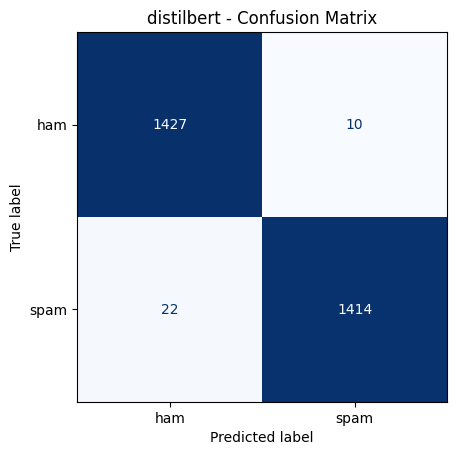

=== roberta_setfit ===
              precision    recall  f1-score   support

         ham     0.9748    0.9944    0.9845      1437
        spam     0.9943    0.9742    0.9842      1436

    accuracy                         0.9843      2873
   macro avg     0.9845    0.9843    0.9843      2873
weighted avg     0.9845    0.9843    0.9843      2873



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


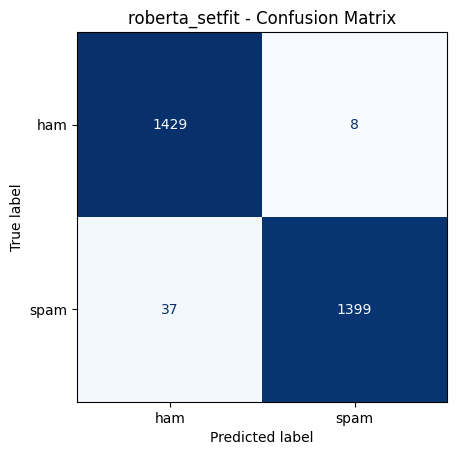

=== flan_t5 ===
              precision    recall  f1-score   support

         ham     0.9821    0.9930    0.9875      1437
        spam     0.9930    0.9819    0.9874      1436

    accuracy                         0.9875      2873
   macro avg     0.9875    0.9875    0.9875      2873
weighted avg     0.9875    0.9875    0.9875      2873



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


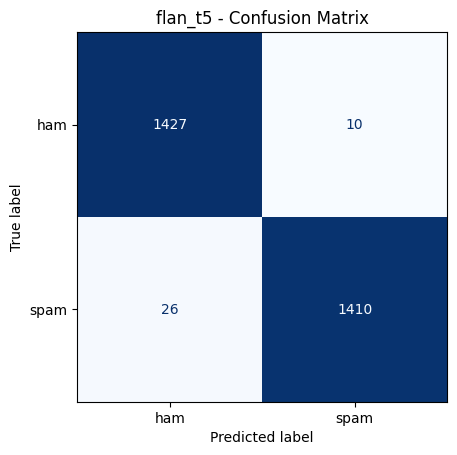

,model,accuracy,macro_f1,spam_precision,spam_recall,ham_fpr,roc_auc,ece,threshold
0,distilbert,0.9889,0.9889,0.9930,0.9847,0.0070,0.9986,0.0081,0.50
1,roberta_setfit,0.9843,0.9843,0.9943,0.9742,0.0056,0.9985,0.0043,0.83
2,flan_t5,0.9875,0.9875,0.9930,0.9819,0.0070,0.9974,0.0058,0.50


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,spam_prevalence,spam_precision,spam_recall,ham_fpr,false_alarms_per_1000_ham,macro_f1
0,distilbert,0.134,0.9678,0.9847,0.0051,5.0647,0.9862
1,roberta_setfit,0.134,0.9682,0.9742,0.0050,4.9569,0.9834
2,flan_t5,0.134,0.9540,0.9819,0.0073,7.3276,0.9813


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
test_results = []
natural_results = []
test_predictions = pd.read_csv(os.path.join(table_folder, "test_predictions.csv"))  # Naive Bayes and Logistic Regression
all_labels = np.concatenate([test_labels, np.zeros(ham_needed, dtype=int)])

for model_name in ["distilbert", "roberta_setfit", "flan_t5"]:
    settings = calibration[model_name]
    probabilities = to_probability(logits[model_name]["test"] / settings["temperature"])
    predictions = (probabilities >= settings["threshold"]).astype(int)
    test_predictions[model_name] = predictions
    test_results.append(test_scores(model_name, test_labels, probabilities, settings["threshold"]))

    print(f"=== {model_name} ===")
    print(classification_report(test_labels, predictions, target_names=["ham", "spam"], digits=4))
    ConfusionMatrixDisplay.from_predictions(test_labels, predictions, display_labels=["ham", "spam"], cmap="Blues", values_format="d", colorbar=False)
    plt.title(f"{model_name} - Confusion Matrix")
    plt.savefig(os.path.join(figure_folder, f"confusion_{model_name}.png"), dpi=150, bbox_inches="tight")
    plt.show()

    # Realistic spam rate (13.4%): test set + extra ham
    all_probabilities = np.concatenate([probabilities, to_probability(logits[model_name]["extra_ham"] / settings["temperature"])])
    scores = test_scores(model_name, all_labels, all_probabilities, settings["threshold"])
    natural_results.append({"model": model_name, "spam_prevalence": all_labels.mean(), "spam_precision": scores["spam_precision"],
                            "spam_recall": scores["spam_recall"], "ham_fpr": scores["ham_fpr"],
                            "false_alarms_per_1000_ham": scores["ham_fpr"] * 1000, "macro_f1": scores["macro_f1"]})

display(pd.DataFrame(test_results).round(4))
display(pd.DataFrame(natural_results).round(4))

In [24]:
# Are two models really different? McNemar test: look only at messages where exactly one model is right.
# If one model wins those messages much more often than 50/50, the difference is significant (p-value < 0.05).
from itertools import combinations

from scipy.stats import binomtest

model_names = ["tfidf_nb", "tfidf_lr", "distilbert", "roberta_setfit", "flan_t5"]
mcnemar_results = []

for first_model, second_model in combinations(model_names, 2):
    first_correct = test_predictions[first_model] == test_labels
    second_correct = test_predictions[second_model] == test_labels
    only_first = int((first_correct & ~second_correct).sum())
    only_second = int((~first_correct & second_correct).sum())
    p_value = binomtest(only_first, only_first + only_second, 0.5).pvalue if only_first + only_second > 0 else 1.0
    mcnemar_results.append({"model_a": first_model, "model_b": second_model, "only_a_correct": only_first,
                            "only_b_correct": only_second, "p_value": p_value, "significant": p_value < 0.05})

mcnemar_table = pd.DataFrame(mcnemar_results)
display(mcnemar_table.round(4))

,model_a,model_b,only_a_correct,only_b_correct,p_value,significant
0,tfidf_nb,tfidf_lr,13,65,0.0000,True
1,tfidf_nb,distilbert,17,79,0.0000,True
2,tfidf_nb,roberta_setfit,23,72,0.0000,True
3,tfidf_nb,flan_t5,13,71,0.0000,True
4,tfidf_lr,distilbert,15,25,0.1539,False
5,tfidf_lr,roberta_setfit,22,19,0.7552,False
6,tfidf_lr,flan_t5,18,24,0.4408,False
7,distilbert,roberta_setfit,25,12,0.0470,True
8,distilbert,flan_t5,17,13,0.5847,False
9,roberta_setfit,flan_t5,12,21,0.1628,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,rank,model,accuracy,macro_f1,spam_precision,spam_recall,ham_fpr,roc_auc,ece,threshold
0,1,distilbert,0.9889,0.9889,0.9930,0.9847,0.0070,0.9986,0.0081,0.50
1,2,flan_t5,0.9875,0.9875,0.9930,0.9819,0.0070,0.9974,0.0058,0.50
2,3,tfidf_lr,0.9854,0.9854,0.9908,0.9798,0.0090,0.9990,0.0066,0.59
3,4,roberta_setfit,0.9843,0.9843,0.9943,0.9742,0.0056,0.9985,0.0043,0.83
4,5,tfidf_nb,0.9673,0.9673,0.9927,0.9415,0.0070,0.9943,0.0111,0.83


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


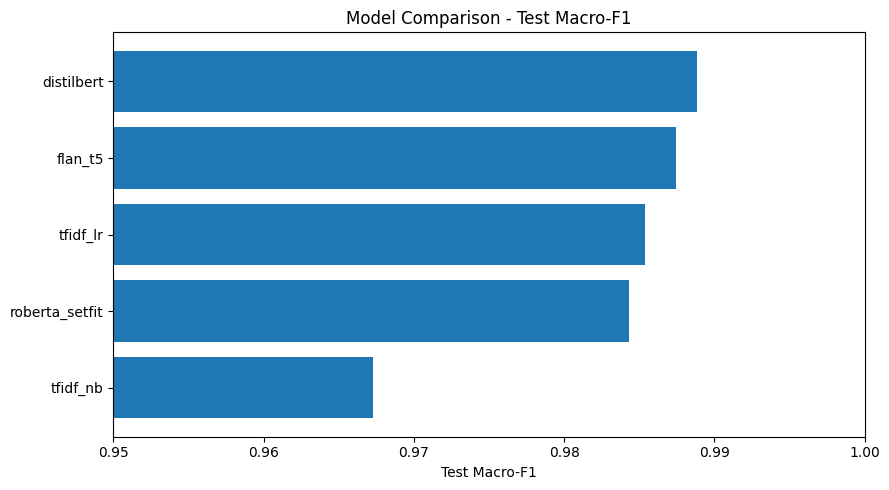

In [25]:
# Final comparison of all five models
final_comparison = save_rows(test_results, "test_results.csv").sort_values("macro_f1", ascending=False).reset_index(drop=True)
final_comparison.insert(0, "rank", range(1, len(final_comparison) + 1))
display(final_comparison.round(4))

plot_data = final_comparison.sort_values("macro_f1")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["model"], plot_data["macro_f1"])
plt.xlabel("Test Macro-F1")
plt.title("Model Comparison - Test Macro-F1")
plt.xlim(0.95, 1)
plt.tight_layout()
plt.show()

## 8. Ambiguous examples

12 borderline messages written by the team. There is no correct answer, so we only compare the spam probability of each model.

In [26]:
# You asked for 5 ambiguous examples but because I wanna to try more about the quality of our project so I added several (5 creates by our self and some from googles)
ambiguous_examples = [{'id': 'A01',
  'category': 'Security alert without a link',
  'text': 'URGENT: your account was locked after an unusual login attempt. Please call the number on the '
          'back of your card.',
  'why_ambiguous': 'Urgent scam-like wording, but it sends the reader to a trusted number and asks for '
                   'nothing.',
  'lean': 'unclear'},
 {'id': 'A02',
  'category': 'One-time code',
  'text': 'Your OTP is 482913. Do NOT share this code with anyone. If you did not request it, call 1500888.',
  'why_ambiguous': 'A normal transactional code, yet the same text appears in account-takeover attempts.',
  'lean': 'ham'},
 {'id': 'A03',
  'category': 'Possible wrong-number opener',
  'text': "Hi, is this still Sarah's number? We met at the conference last month and I wanted to follow up.",
  'why_ambiguous': 'Could be a real contact or the opener of a trust-building scam. Nothing in the text '
                   'decides it.',
  'lean': 'unclear'},
 {'id': 'A04',
  'category': 'Family impersonation',
  'text': "Hey it's mum, I broke my phone so this is my new number. Can you text me back when you're free?",
  'why_ambiguous': 'Sounds personal, and it is also the first step of a well-known family-impersonation '
                   'scam.',
  'lean': 'unclear'},
 {'id': 'A05',
  'category': 'Delivery notice with a link',
  'text': 'Your package could not be delivered today. Reschedule here: https://track.example.com/a8f2',
  'why_ambiguous': 'Couriers send this every day, and so do parcel scammers. Only the sender and link can '
                   'separate them.',
  'lean': 'unclear'},
 {'id': 'A06',
  'category': 'Spam words in a personal message',
  'text': "You won!! Free drinks on me tonight at Joe's, come celebrate my promotion with us",
  'why_ambiguous': 'Uses the words won, free, and promotion, but it is an invitation between friends.',
  'lean': 'ham'},
 {'id': 'A07',
  'category': 'Opted-in business promotion',
  'text': 'Reminder: 20% off your next check-up if you book before Friday. Reply STOP to unsubscribe. - '
          'Bright Smile Dental',
  'why_ambiguous': 'A legitimate business and possibly wanted by the recipient, yet still marketing.',
  'lean': 'spam'},
 {'id': 'A08',
  'category': 'Very short and urgent',
  'text': "Call me now, it's urgent",
  'why_ambiguous': 'Too short to judge. It suits both a worried friend and a callback scam.',
  'lean': 'ham'},
 {'id': 'A09',
  'category': 'Too-good job offer',
  'text': 'We reviewed your CV and would like to offer you a part-time role at $45/hour from home. WhatsApp '
          'HR on +1 555 010 7788.',
  'why_ambiguous': 'Recruiters do text applicants, but high pay and moving the chat to WhatsApp are scam '
                   'signs.',
  'lean': 'spam'},
 {'id': 'A10',
  'category': 'Billing receipt with a link',
  'text': 'Thanks for your payment of $120.50. Your balance is now $0. Questions? Visit example.com/billing',
  'why_ambiguous': 'A plain receipt that has the money amount and link typical of spam.',
  'lean': 'ham'},
 {'id': 'A11',
  'category': 'Charity appeal',
  'text': 'Flood relief: your $5 can feed a family this week. Text GIVE to 70123. Msg rates apply.',
  'why_ambiguous': 'Real charities fundraise this way, and scammers copy the format after disasters.',
  'lean': 'unclear'},
 {'id': 'A12',
  'category': 'Two-word question',
  'text': 'Free tonight?',
  'why_ambiguous': 'Contains a classic spam word, and has almost no other context.',
  'lean': 'ham'}]

In [27]:
import joblib

ambiguous_texts = [example["text"] for example in ambiguous_examples]
ambiguous_results = pd.DataFrame({"id": [example["id"] for example in ambiguous_examples],
                                   "category": [example["category"] for example in ambiguous_examples]})
all_calibration = {**json.load(open(os.path.join(model_folder, "calibration.json"))), **calibration}

# Naive Bayes and Logistic Regression (saved by the traditional notebook)
for model_name in ["tfidf_nb", "tfidf_lr"]:
    model = joblib.load(os.path.join(model_folder, f"{model_name}.joblib"))
    model_logits = to_logit(model.predict_proba([normalize(text) for text in ambiguous_texts])[:, 1])
    ambiguous_results[model_name] = to_probability(model_logits / all_calibration[model_name]["temperature"])

# Transformer models
model_logits = transformer_logits(distilbert_folder, [normalize(text) for text in ambiguous_texts])
ambiguous_results["distilbert"] = to_probability(model_logits / calibration["distilbert"]["temperature"])
model_logits = transformer_logits(flan_t5_folder, [normalize_lowercase(text) for text in ambiguous_texts])
ambiguous_results["flan_t5"] = to_probability(model_logits / calibration["flan_t5"]["temperature"])
spam_probability = setfit_model.predict_proba([normalize_lowercase(text) for text in ambiguous_texts], as_numpy=True)[:, 1].astype(float)
ambiguous_results["roberta_setfit"] = to_probability(to_logit(spam_probability) / calibration["roberta_setfit"]["temperature"])

# Do the models disagree about spam or ham?
decisions = pd.DataFrame({model_name: ambiguous_results[model_name] >= all_calibration[model_name]["threshold"] for model_name in model_names})
ambiguous_results["models_disagree"] = decisions.nunique(axis=1) > 1
display(ambiguous_results.round(3))
print("Models disagree on", ambiguous_results["models_disagree"].sum(), "of", len(ambiguous_results), "messages")

,id,category,tfidf_nb,tfidf_lr,distilbert,flan_t5,roberta_setfit,models_disagree
0,A01,Security alert without a link,1.000,0.981,0.981,0.985,0.970,False
1,A02,One-time code,0.998,0.997,0.943,0.987,0.832,False
2,A03,Possible wrong-number opener,0.146,0.045,0.013,0.005,0.043,False
3,A04,Family impersonation,0.012,0.259,0.034,0.006,0.121,False
4,A05,Delivery notice with a link,0.999,1.000,0.995,0.997,0.999,False
5,A06,Spam words in a personal message,0.465,0.336,0.013,0.088,0.723,False
6,A07,Opted-in business promotion,0.979,0.989,0.956,0.994,0.982,False
7,A08,Very short and urgent,0.093,0.061,0.006,0.066,0.032,False
8,A09,Too-good job offer,0.998,1.000,0.990,0.994,0.994,False
9,A10,Billing receipt with a link,1.000,1.000,0.996,0.998,0.999,False


Models disagree on 0 of 12 messages


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 9. Robustness

Spammers change their messages to avoid filters. We change every test message in six ways and check how the results move:

| Change | Example |
|---|---|
| lowercase | `WIN NOW` → `win now` |
| strip_punctuation | `Call now!` → `Call now` |
| leetspeak | `free` → `fr33` (each a, e, i, o, s changes with 30% chance) |
| character_spacing | `prize` → `p r i z e` (one word per message) |
| swap_url_domain | every link → `https://replacement.example.com` |
| append_benign | add `See you soon.` at the end |

The label of the message stays the same, so a robust model keeps the same decision. `flip_rate` is the share of messages whose decision changed.

In [28]:
import string

leet = {"a": "4", "e": "3", "i": "1", "o": "0", "s": "5"}
perturbations = ["lowercase", "strip_punctuation", "leetspeak", "character_spacing", "swap_url_domain", "append_benign"]

def perturb(text, kind, random_generator):
    if kind == "lowercase":
        return text.lower()
    if kind == "strip_punctuation":
        return text.translate(str.maketrans("", "", string.punctuation))
    if kind == "leetspeak":
        return "".join(leet[character.lower()] if character.lower() in leet and random_generator.random() < 0.3 else character for character in text)
    if kind == "character_spacing":
        words = list(re.finditer(r"\b[A-Za-z]{3,}\b", text))
        if not words:
            return text
        word = words[int(random_generator.integers(len(words)))]
        return text[:word.start()] + " ".join(word.group()) + text[word.end():]
    if kind == "swap_url_domain":
        # keep the domain part of an email address, replace real links and the dataset's <URL> mask
        def replace(match):
            return match.group() if match.start() and text[match.start() - 1] == "@" else "https://replacement.example.com"
        return re.sub(r"<URL>", "https://replacement.example.com", url_pattern.sub(replace, text), flags=re.I)
    if kind == "append_benign":
        return text + " See you soon."

# Calibrated spam probability of any of the five models (same steps as app.py)
classical_models = {model_name: joblib.load(os.path.join(model_folder, f"{model_name}.joblib")) for model_name in ["tfidf_nb", "tfidf_lr"]}

def spam_probability(model_name, texts):
    if model_name in classical_models:
        model_logits = to_logit(classical_models[model_name].predict_proba([normalize(text) for text in texts])[:, 1])
    elif model_name == "distilbert":
        model_logits = transformer_logits(distilbert_folder, [normalize(text) for text in texts])
    elif model_name == "flan_t5":
        model_logits = transformer_logits(flan_t5_folder, [normalize_lowercase(text) for text in texts])
    else:
        spam_scores = setfit_model.predict_proba([normalize_lowercase(text) for text in texts], batch_size=32, as_numpy=True)[:, 1].astype(float)
        model_logits = to_logit(spam_scores)
    return to_probability(model_logits / all_calibration[model_name]["temperature"])

print(perturb("WINNER!! Claim your free prize at www.win.com now", "leetspeak", np.random.default_rng(42)))

WINNER!! Claim y0ur free priz3 at www.win.com now


In [29]:
# Run every change on the whole test set (about 10 minutes on a T4 GPU)
robustness_results = []
test_texts = test_data["text"].tolist()

for model_name in model_names:
    threshold = all_calibration[model_name]["threshold"]
    original_decisions = spam_probability(model_name, test_texts) >= threshold
    original_recall = original_decisions[test_labels == 1].mean()
    original_fpr = original_decisions[test_labels == 0].mean()

    for kind in perturbations:
        random_generator = np.random.default_rng(42)  # same random changes for every model
        changed_texts = [perturb(text, kind, random_generator) for text in test_texts]
        decisions = spam_probability(model_name, changed_texts) >= threshold
        robustness_results.append({
            "model": model_name,
            "perturbation": kind,
            "spam_recall": decisions[test_labels == 1].mean(),
            "ham_fpr": decisions[test_labels == 0].mean(),
            "recall_change": decisions[test_labels == 1].mean() - original_recall,
            "fpr_change": decisions[test_labels == 0].mean() - original_fpr,
            "flip_rate": (decisions != original_decisions).mean(),
        })
    print(model_name, "done")

robustness_table = pd.DataFrame(robustness_results)
display(robustness_table.round(4))

tfidf_nb done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

tfidf_lr done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


distilbert done
roberta_setfit done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


flan_t5 done


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,perturbation,spam_recall,ham_fpr,recall_change,fpr_change,flip_rate
0,tfidf_nb,lowercase,0.9331,0.0070,-0.0084,0.0000,0.0049
1,tfidf_nb,strip_punctuation,0.9213,0.0070,-0.0202,0.0000,0.0129
2,tfidf_nb,leetspeak,0.9088,0.0188,-0.0327,0.0118,0.0334
3,tfidf_nb,character_spacing,0.9380,0.0070,-0.0035,0.0000,0.0094
4,tfidf_nb,swap_url_domain,0.9415,0.0070,0.0000,0.0000,0.0000
5,tfidf_nb,append_benign,0.8935,0.0028,-0.0481,-0.0042,0.0261
6,tfidf_lr,lowercase,0.9756,0.0090,-0.0042,0.0000,0.0021
7,tfidf_lr,strip_punctuation,0.9617,0.0084,-0.0181,-0.0007,0.0122
8,tfidf_lr,leetspeak,0.9610,0.0111,-0.0188,0.0021,0.0167
9,tfidf_lr,character_spacing,0.9749,0.0070,-0.0049,-0.0021,0.0042


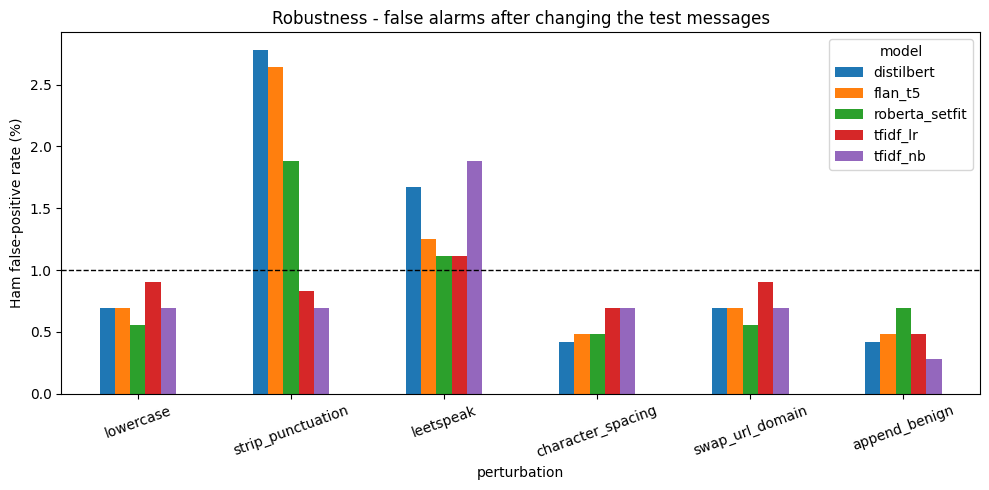

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [30]:
# False alarms on legitimate messages after each change (the dashed line is the 1% target)
plot_data = robustness_table.pivot(index="perturbation", columns="model", values="ham_fpr").loc[perturbations] * 100
plot_data.plot(kind="bar", figsize=(10, 5))
plt.axhline(1, color="black", linestyle="--", linewidth=1)
plt.ylabel("Ham false-positive rate (%)")
plt.title("Robustness - false alarms after changing the test messages")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(figure_folder, "robustness.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10. Error analysis (DistilBERT)

We read every test message that DistilBERT got wrong and gave it one category. The categories are stored by row number in `test.csv`, so no message text is written in this notebook. If DistilBERT is trained again, new errors show up as "Not reviewed yet" and need a category.

In [31]:
# Every test message that DistilBERT got wrong
distilbert_probability = to_probability(logits["distilbert"]["test"] / calibration["distilbert"]["temperature"])
distilbert_decisions = (distilbert_probability >= calibration["distilbert"]["threshold"]).astype(int)

errors = test_data[distilbert_decisions != test_labels].copy()
errors["error_type"] = np.where(errors["label"] == 0, "false positive (ham flagged)", "false negative (spam missed)")
errors["spam_probability"] = distilbert_probability[distilbert_decisions != test_labels].round(3)

print("Errors:", len(errors), "| false positives:", (errors["label"] == 0).sum(), "| false negatives:", (errors["label"] == 1).sum())
pd.set_option("display.max_colwidth", 120)
display(errors[["text", "error_type", "spam_probability"]])

Errors: 32 | false positives: 10 | false negatives: 22


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,text,error_type,spam_probability
20,Hi be u Johan it's Kallie .. we msged on Coffee Meets Bagel before when I come down to hang with my grandmother but ...,false negative (spam missed),0.004
40,Hi try to call u regard online betting acct but still can't reach u May I know which acct u interested Soccer Casino...,false negative (spam missed),0.097
91,The 2 oz guy is being kinda flaky but one friend is interested in picking up $ <#> worth tonight if possible,false positive (ham flagged),0.603
251,"Hello Sajitha, I'm currently in the US and need assistance with resetting my hearing aids. Could you please help? I ...",false negative (spam missed),0.487
266,"What is the color of your eyes and hair? Please write back, I'm eagerly waiting for your response.",false negative (spam missed),0.044
277,In 1935 american govt. had killed a person on 1st satday of Aug the next day his frend died commiting suicide.In his...,false positive (ham flagged),0.647
530,"Hey, I am submitting your name for the next committee for astro club.I have not decide on positions so I will let yo...",false negative (spam missed),0.207
754,DINE-IN open now at our Kurri rd Branch!!! Visit now and enjoy 10% off on all Dine-in & Takeaway orders.,false negative (spam missed),0.121
865,delivery due tomorrow Friday XX Jun 2019. if not home we'll leave it in a safe place See,false negative (spam missed),0.110
972,2/2 146tf150p,false negative (spam missed),0.098


In [32]:
# Category of each error, given by the team after reading the message (key = row number in test.csv)
conversational = "Conversational spam / romance / job scam"
short = "Short or ambiguous message"
transactional = "Transactional / OTP resembles promotion"
promotion = "Plain promotion missed"
label_noise = "Probable published-label noise"
code_mixed = "Non-English or code-mixed"
obfuscated = "Obfuscated wording"

error_categories = {
    20: conversational, 40: conversational, 91: short, 251: conversational, 266: conversational, 277: short,
    530: conversational, 754: promotion, 865: transactional, 972: short, 1019: transactional, 1105: short,
    1239: short, 1278: transactional, 1287: conversational, 1562: conversational, 1602: promotion, 1634: conversational,
    1674: code_mixed, 1992: conversational, 2108: obfuscated, 2176: short, 2195: transactional, 2233: short,
    2283: code_mixed, 2374: transactional, 2454: promotion, 2557: label_noise, 2649: label_noise, 2666: conversational,
    2721: label_noise, 2817: conversational,
}

errors["category"] = [error_categories.get(row, "Not reviewed yet") for row in errors.index]
error_table = errors.groupby("category").agg(count=("label", "size"),
                                            false_positives=("label", lambda labels: int((labels == 0).sum())),
                                            false_negatives=("label", lambda labels: int((labels == 1).sum())))
error_table = error_table.sort_values("count", ascending=False, kind="stable").reset_index()
error_table.loc[len(error_table)] = ["total", error_table["count"].sum(), error_table["false_positives"].sum(), error_table["false_negatives"].sum()]
display(error_table)
display(errors[["text", "error_type", "category"]].sort_values("category"))

,category,count,false_positives,false_negatives
0,Conversational spam / romance / job scam,11,0,11
1,Short or ambiguous message,7,6,1
2,Transactional / OTP resembles promotion,5,2,3
3,Plain promotion missed,3,0,3
4,Probable published-label noise,3,1,2
5,Non-English or code-mixed,2,1,1
6,Obfuscated wording,1,0,1
7,total,32,10,22


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,text,error_type,category
20,Hi be u Johan it's Kallie .. we msged on Coffee Meets Bagel before when I come down to hang with my grandmother but ...,false negative (spam missed),Conversational spam / romance / job scam
2666,Are you at home? you'll never guess what happened to me today.. This is my temporary number from now on you can save...,false negative (spam missed),Conversational spam / romance / job scam
1992,m jeff 22.wanna chat?care to intro pls...,false negative (spam missed),Conversational spam / romance / job scam
1634,"Dear customer, we kindly invite you to our head office tonight at 08:45pm. and please bring an identification to ver...",false negative (spam missed),Conversational spam / romance / job scam
1287,You need to get tested for Gonorrhoea and chlamydia ASAP. We suspect you will test positive to gonorrhea. May I ask ...,false negative (spam missed),Conversational spam / romance / job scam
530,"Hey, I am submitting your name for the next committee for astro club.I have not decide on positions so I will let yo...",false negative (spam missed),Conversational spam / romance / job scam
1562,Hello I'm Shirley be you Mark I'm not sure if I get the phone number wrong I make the wrong call and I'm so sorryI h...,false negative (spam missed),Conversational spam / romance / job scam
2817,Hey its Chris Based on our conversation here be the link you be interested in ..,false negative (spam missed),Conversational spam / romance / job scam
40,Hi try to call u regard online betting acct but still can't reach u May I know which acct u interested Soccer Casino...,false negative (spam missed),Conversational spam / romance / job scam
251,"Hello Sajitha, I'm currently in the US and need assistance with resetting my hearing aids. Could you please help? I ...",false negative (spam missed),Conversational spam / romance / job scam


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11. Saving the results

In [33]:
# Thresholds and temperatures (read by app.py -> will be our applications)
all_calibration_file = json.load(open(os.path.join(model_folder, "calibration.json")))
all_calibration_file["distilbert"] = calibration["distilbert"]
with open(os.path.join(model_folder, "calibration.json"), "w") as file:
    json.dump(all_calibration_file, file, indent=2)
with open(os.path.join(model_folder, "calibration_extensions.json"), "w") as file:
    json.dump({model_name: calibration[model_name] for model_name in ["roberta_setfit", "flan_t5"]}, file, indent=2)

# Results tables
save_rows(natural_results, "natural_prevalence.csv")
mcnemar_table.to_csv(os.path.join(table_folder, "mcnemar.csv"), index=False)
ambiguous_results.to_csv(os.path.join(table_folder, "ambiguous_predictions.csv"), index=False)
print("Saved:", model_folder, "and", table_folder)
robustness_table.to_csv(os.path.join(table_folder, "robustness.csv"), index=False)
error_table.to_csv(os.path.join(table_folder, "error_analysis.csv"), index=False)

Saved: /content/drive/MyDrive/SpamLens/models and /content/drive/MyDrive/SpamLens/results/tables


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
